In [114]:
from abc import ABC, abstractmethod
from dataclasses import dataclass, field
import numpy as np
import matplotlib.pyplot as plt

In [115]:
@dataclass
class Problem:
    data: np.ndarray = field(default_factory=lambda: np.empty((0, 0)))
    values: np.ndarray = field(default_factory=lambda: np.empty(0))

    def __post_init__(self):
        self.data = np.asarray(self.data, dtype=float)
        self.values = np.asarray(self.values).reshape(-1)
        if self.data.size and self.data.ndim != 2:
            raise ValueError("data must have shape (n_samples, n_features)")
        if self.data.size and len(self.data) != len(self.values):
            raise ValueError("data and values must contain the same number of samples")

    @property
    def classes(self):
        return np.unique(self.values)



def as_2d(X):
    X = np.asarray(X, dtype=float)
    if X.ndim == 1:
        return X.reshape(1, -1)
    if X.ndim == 2:
        return X
    raise ValueError("X must be 1D or 2D")

def validate_binary_labels(y):
    y = np.asarray(y, dtype=float).reshape(-1)
    if set(np.unique(y).tolist()) != {-1.0, 1.0}:
        raise ValueError("y must contain exactly -1 and +1")
    return y

Двойственная задача и SMO
Для soft-margin SVM решается
$$
\max_\alpha \sum_i\alpha_i-
\frac12\sum_{i,j}\alpha_i\alpha_jy_iy_jK(x_i,x_j),
$$
при условиях
$$
0\le\alpha_i\le C,\qquad \sum_i\alpha_i y_i=0.
$$
После обучения
$$
f(x)=\sum_{i\in SV}(\alpha_i y_i)K(x_i,x)+b.
$$

In [116]:
class Kernel(ABC):
    """Стратегия вычисления матрицы K(X, Z)."""

    @abstractmethod
    def __call__(self, X: np.ndarray, Z: np.ndarray) -> np.ndarray:
        raise NotImplementedError
    
    @abstractmethod
    def __repr__(self) -> str:
        raise NotImplementedError


class LinearKernel(Kernel):
    def __call__(self, X, Z):
        return X @ Z.T
    
    def __repr__(self):
        return "LinearKernel"


@dataclass(frozen=True)
class PolynomialKernel(Kernel):
    degree: int = 3
    gamma: float | None = None
    coef0: float = 1.0

    def __call__(self, X, Z):
        gamma = 1.0 / X.shape[1] if self.gamma is None else self.gamma
        return (gamma * (X @ Z.T) + self.coef0) ** self.degree
    
    def __repr__(self):
        return "PolynomialKernel"


@dataclass(frozen=True)
class RBFKernel(Kernel):
    gamma: float = 1.0

    def __call__(self, X, Z):
        X2 = np.sum(X * X, axis=1)[:, None]
        Z2 = np.sum(Z * Z, axis=1)[None, :]
        sq_dist = np.maximum(X2 + Z2 - 2.0 * X @ Z.T, 0.0)
        return np.exp(-self.gamma * sq_dist)
    
    def __repr__(self):
        return "RBFKernel"

In [117]:
x = np.array([[1, 2], [3, 4]])
z = np.array([[5, 6], [7, 8]])
print(LinearKernel()(x, z))

[[17 23]
 [39 53]]


Soft-margin SVM (primal):

$$
\min_{w,b,\xi}\;
\frac{1}{2}\|w\|^2
+
C\sum_i \xi_i
\qquad
\text{s.t.}
\qquad
 y_i\left(w^\top x_i+b\right)\ge 1-\xi_i,
\qquad
\xi_i\ge 0
$$

Лагранжиан с множителями $\alpha_i \ge 0$ и $\mu_i \ge 0$.
$$
\mathcal L
=
\frac12\|w\|^2
+
C\sum_i\xi_i
+
\sum_i\alpha_i
\left[
1-y_i(w^\top x_i+b)-\xi_i
\right]
-
\sum_i\mu_i\xi_i
$$

Условия стационарности:

$$
w=\sum_i \alpha_i y_i x_i,
\qquad
\sum_i \alpha_i y_i=0,
\qquad
\alpha_i+\mu_i=C
\;\Longrightarrow\;
0\le \alpha_i\le C
$$

Двойственная задача:

$$
\min_{\alpha}\;
f(\alpha)
=
\frac{1}{2}\alpha^\top Q\alpha
-
\mathbf{1}^\top\alpha
\qquad
\text{s.t.}
\qquad
y^\top\alpha=0,
\qquad
0\le\alpha_i\le C
$$

$$
Q_{ij}=y_i y_j K(x_i,x_j)
$$


In [118]:
class DualProblem:
    """Двойственная задача soft-margin SVM: данные (K, y, C) и вся «математика» задачи.

    Ничего не знает про то, КАК задача решается — только что такое
    цель, ограничения и условия оптимальности (KKT).
    """

    def __init__(self, K: np.ndarray, y: np.ndarray, C: float):
        self.K, self.y, self.C = K, y, C

    @property
    def n(self) -> int:
        return len(self.y)

    def objective(self, alpha):
        """W(alpha) = sum(alpha) - 1/2 * (alpha*y)^T K (alpha*y)."""
        ay = alpha * self.y
        return alpha.sum() - 0.5 * ay @ self.K @ ay

    def errors(self, alpha, b):
        """E_k = f(x_k) - y_k на обучающей выборке."""
        return self.K @ (alpha * self.y) + b - self.y

    def violates_kkt(self, i, alpha_i, E_i, tol, eps=1e-9):
        r = self.y[i] * E_i
        return (r < -tol and alpha_i < self.C - eps) or (r > tol and alpha_i > eps)

    def bounds(self, i, j, alpha):
        """Отрезок [L, H] допустимых alpha_j при фиксированных остальных alpha."""
        if self.y[i] != self.y[j]:
            return max(0.0, alpha[j] - alpha[i]), min(
                self.C, self.C + alpha[j] - alpha[i]
            )
        return max(0.0, alpha[i] + alpha[j] - self.C), min(self.C, alpha[i] + alpha[j])

    def curvature(self, i, j):
        """eta = 2K_ij - K_ii - K_jj = -||phi(x_i) - phi(x_j)||^2 <= 0."""
        return 2.0 * self.K[i, j] - self.K[i, i] - self.K[j, j]

$$
0\le\alpha_i,\alpha_j\le C.
$$

Вся логика SMO в одном предложении
На каждой итерации алгоритм:
1. находит точку, нарушающую KKT;
2. выбирает вторую точку;
3. меняет пару $(\alpha_i,\alpha_j)$, сохраняя
   $\sum_i\alpha_i y_i=0;$
4. ограничивает коэффициенты интервалом $[L,H]$;
5. обновляет $b$;
6. быстро обновляет ошибки.
После сходимости классификатор строится как:
$$
f(x)=
\sum_i\alpha_i y_iK(x_i,x)+b.
$$

iterations — общее число проходов;

passes — сколько подряд проходов не было изменений.

In [119]:
@dataclass
class DualSolution:
    alpha: np.ndarray
    b: float
    n_iter: int
    converged: bool


@dataclass
class _State:
    """Изменяемое состояние SMO: то, что меняется от шага к шагу."""

    alpha: np.ndarray
    b: float
    E: np.ndarray


@dataclass(frozen=True)
class SMOSolver:
    """Упрощённый SMO: за шаг оптимизирует пару (alpha_i, alpha_j) аналитически."""

    tol: float = 1e-3
    max_passes: int = 1000
    max_iter: int = 10_000

    def solve(self, problem: DualProblem) -> DualSolution:
        alpha = np.zeros(problem.n)
        state = _State(alpha, 0.0, problem.errors(alpha, 0.0))

        for iteration in range(1, self.max_iter + 1):
            changed = 0
            for i in range(problem.n):
                if problem.violates_kkt(i, state.alpha[i], state.E[i], self.tol):
                    changed += self._optimize_with_best_partner(problem, state, i)
            if changed == 0:                      # состояние больше не изменится
                return DualSolution(state.alpha, state.b, iteration, True)

        return DualSolution(state.alpha, state.b, self.max_iter, False)

    def _optimize_with_best_partner(self, problem, state, i) -> bool:
        """Пробуем j по убыванию |E_i - E_j|, пока какой-то шаг не сработает."""
        for j in np.argsort(-np.abs(state.E[i] - state.E)):
            if j != i and self._step(problem, state, i, int(j)):
                return True
        return False

    @staticmethod
    def _step(p: DualProblem, s: _State, i, j) -> bool:
        """Один шаг по паре (i, j). Возвращает True, если alpha изменились."""
        yi, yj = p.y[i], p.y[j]
        ai, aj = s.alpha[i], s.alpha[j]
        L, H = p.bounds(i, j, s.alpha)
        eta = p.curvature(i, j)
        if H - L < 1e-15 or eta >= 0.0:
            return False

        aj_new = np.clip(aj - yj * (s.E[i] - s.E[j]) / eta, L, H)
        if abs(aj_new - aj) < 1e-8:
            return False
        ai_new = ai + yi * yj * (aj - aj_new)
        di, dj = ai_new - ai, aj_new - aj

        # смещение b: берём то, при котором KKT выполнено точно для «свободного» alpha
        K = p.K
        b1 = s.b - s.E[i] - yi * di * K[i, i] - yj * dj * K[i, j]
        b2 = s.b - s.E[j] - yi * di * K[i, j] - yj * dj * K[j, j]
        if 0.0 < ai_new < p.C:
            b_new = b1
        elif 0.0 < aj_new < p.C:
            b_new = b2
        else:
            b_new = 0.5 * (b1 + b2)

        # ошибки обновляем инкрементально, без пересчёта K @ (alpha*y)
        s.E += yi * di * K[:, i] + yj * dj * K[:, j] + (b_new - s.b)
        s.alpha[i], s.alpha[j], s.b = ai_new, aj_new, b_new
        return True

In [120]:
class BaseSVM(ABC):
    @abstractmethod
    def fit(self, X, y):
        raise NotImplementedError

    @abstractmethod
    def decision_function(self, X):
        raise NotImplementedError

    def predict(self, X):
        return np.where(self.decision_function(X) >= 0.0, 1, -1)

    def score(self, X, y):
        y = np.asarray(y).reshape(-1)
        return float(np.mean(self.predict(X) == y))

In [127]:
class BinaryKernelSVM(BaseSVM):
    """Бинарный soft-margin SVM: ядро + решатель двойственной задачи."""

    def __init__(
        self, C=1.0, kernel: Kernel | None = None, solver: SMOSolver | None = None
    ):
        if C <= 0:
            raise ValueError("C must be positive")
        self.C = float(C)
        self.kernel = kernel if kernel is not None else RBFKernel()
        self.solver = solver if solver is not None else SMOSolver()

    def fit(self, X, y):
        X = as_2d(X)
        y = validate_binary_labels(y)
        if len(X) != len(y):
            raise ValueError("X and y must have the same number of rows")

        problem = DualProblem(self.kernel(X, X), y, self.C)
        self.solution_ = self.solver.solve(problem)

        sv = self.solution_.alpha > 1e-7
        self.support_vectors_ = X[sv]
        self.dual_coef_ = (self.solution_.alpha * y)[sv]  # alpha_i * y_i
        self.intercept_ = self.solution_.b
        return self

    def decision_function(self, X):
        if not hasattr(self, "dual_coef_"):
            raise RuntimeError("Call fit before prediction")
        X = as_2d(X)
        if X.shape[1] != self.support_vectors_.shape[1]:
            raise ValueError("X has an invalid number of features")
        return self.kernel(X, self.support_vectors_) @ self.dual_coef_ + self.intercept_
    
    def draw(self, X, y, ax=None, title=None):
        if title is None:
            title = f"{self.kernel}"
        X = as_2d(X)
        y = validate_binary_labels(y)
        if X.shape[1] != 2:
            raise ValueError("plot supports exactly two features")
        if ax is None:
            _, ax = plt.subplots(figsize=(6, 5))

        xx, yy = self._grid(X)
        zz = self.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

        ax.contourf(xx, yy, zz, levels=30, cmap="coolwarm", alpha=0.18)
        ax.contour(
            xx,
            yy,
            zz,
            levels=[-1, 0, 1],
            colors=["blue", "black", "red"],
            linestyles=["--", "-", "--"],
            linewidths=[1, 2, 1],
        )
        for label, color in ((-1, "tab:blue"), (1, "tab:red")):
            ax.scatter(*X[y == label].T, c=color, label=f"{label:+d}", edgecolor="k")
        if hasattr(self, "support_vectors_"):
            ax.scatter(
                *self.support_vectors_.T,
                s=150,
                facecolors="none",
                edgecolors="gold",
                linewidths=2,
                label="support vectors",
            )
        ax.set(xlabel="x1", ylabel="x2", title=title or type(self).__name__)
        ax.legend()
        return ax

    @staticmethod
    def _grid(X, n = 300):
        pad = 0.15 * np.ptp(X, axis=0)
        pad[pad == 0] = 1.0
        lo, hi = X.min(axis=0) - pad, X.max(axis=0) + pad
        return np.meshgrid(
            np.linspace(lo[0], hi[0], n),
            np.linspace(lo[1], hi[1], n),
        )

Polynomial degree=2 support vectors: 6 iterations: 251 converged: True
RBF support vectors: 22 iterations: 21 converged: True


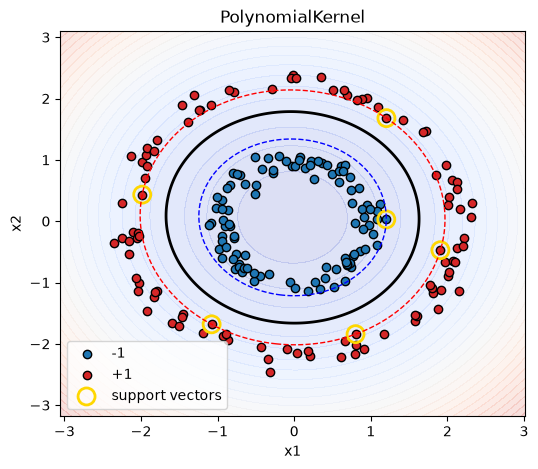

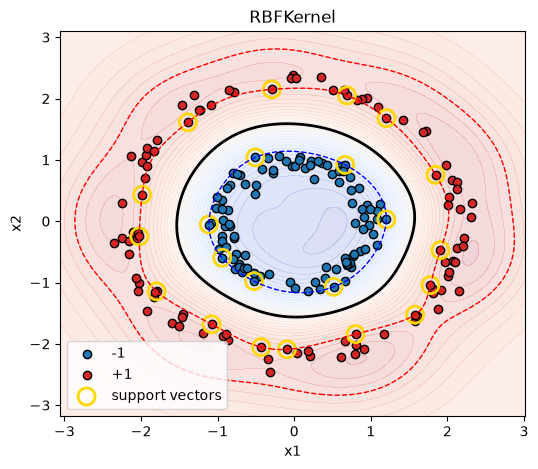

In [128]:
rng = np.random.default_rng(7)
n_per_class = 100

angles_inner = rng.uniform(0, 2 * np.pi, n_per_class)
angles_outer = rng.uniform(0, 2 * np.pi, n_per_class)
r_inner = 1.0 + rng.normal(0, 0.10, n_per_class)
r_outer = 2.2 + rng.normal(0, 0.12, n_per_class)

X_inner = np.c_[r_inner * np.cos(angles_inner), r_inner * np.sin(angles_inner)]
X_outer = np.c_[r_outer * np.cos(angles_outer), r_outer * np.sin(angles_outer)]
X = np.vstack([X_inner, X_outer])
y = np.r_[-np.ones(n_per_class), np.ones(n_per_class)]

solver = SMOSolver()
models = {
    "Polynomial degree=2": BinaryKernelSVM(
        C=10.0, kernel=PolynomialKernel(degree=2, gamma=1.0, coef0=1.0), solver=solver
    ),
    "RBF": BinaryKernelSVM(C=10.0, kernel=RBFKernel(gamma=1.0), solver=solver),
}

for name, model in models.items():
    model.fit(X, y)
    print(
        name,
        "support vectors:",
        len(model.support_vectors_),
        "iterations:",
        model.solution_.n_iter,
        "converged:",
        model.solution_.converged,
    )
    model.draw(X, y)


accuracy: 0.985
support vectors: 11
iterations: 46 converged: True


<Axes: title={'center': 'LinearKernel'}, xlabel='x1', ylabel='x2'>

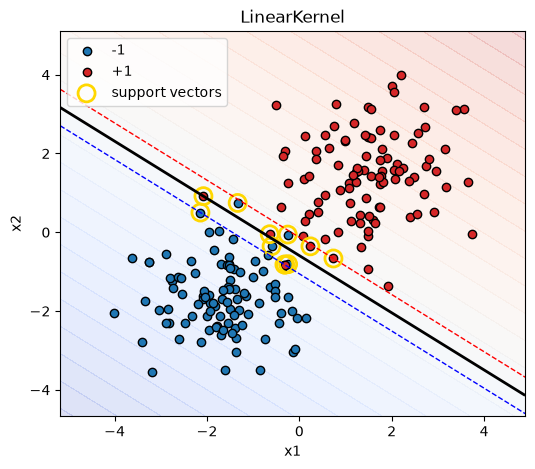

In [135]:
rng = np.random.default_rng(7)
n_per_class = 100

X_neg = rng.normal(loc=[-1.5, -1.5], scale=1.0, size=(n_per_class, 2))
X_pos = rng.normal(loc=[+1.5, +1.5], scale=1.1, size=(n_per_class, 2))
X = np.vstack([X_neg, X_pos])
y = np.r_[-np.ones(n_per_class), np.ones(n_per_class)]

solver = SMOSolver()
model = BinaryKernelSVM(C=10.0, kernel=LinearKernel(), solver=solver)
model.fit(X, y)

print("accuracy:", model.score(X, y))
print("support vectors:", len(model.support_vectors_))
print("iterations:", model.solution_.n_iter, "converged:", model.solution_.converged)
model.draw(X, y)